# ILINet

Online conformal prediction of weekly influenza-like illness using a temporal convolutional network (TCN).


In [1]:
# Locate the project root.
from pathlib import Path
import sys
_PROJECT_CANDIDATES = (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
PROJECT_ROOT = next((p for p in _PROJECT_CANDIDATES if (p / "cp_methods.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project directory.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"

import contextlib
from functools import partial
from importlib.metadata import version
import io
from tempfile import TemporaryDirectory
import platform
import time
import random

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image, display
import torch
from darts import TimeSeries
from darts.datasets import ILINetDataset
from darts.models import TCNModel
from darts.timeseries import concatenate
from pytorch_lightning.callbacks import EarlyStopping
from threadpoolctl import threadpool_limits

import cp_methods as cpm

TARGET_COMPONENT = "% WEIGHTED ILI"
TRAIN_FRAC = 0.70
VAL_FRAC = 0.10
IN_LEN = 26
ALPHA = 0.10
R = 52
SEED = 42
BOOT_BLOCK_LEN = 26
BOOT_REPS = 1_000
ROLLING_WINDOW = 26
SPCI_W_LAG = 8
SPCI_T_TRAIN = R
SPCI_REFIT_EVERY = 1
N_THREADS = 1
ACCELERATOR = (
    "gpu" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
REFERENCE_DATE = "2020-03-01"

METHOD_ORDER = ["cp", "lcp", "aci", "dtaci", "cop", "lqt", "spci", "olcp", "olcph"]
LABELS = {
    "cp": "CP", "lcp": "LCP", "aci": "ACI", "dtaci": "DtACI",
    "cop": "COP", "lqt": "LQT", "spci": "SPCI",
    "olcp": "OLCP", "olcph": "OLCP-Hedge",
}
# Run SPCI last.
METHOD_RUNNERS = {
    "cp": cpm.eval_cp,
    "cop": cpm.eval_cop,
    "lqt": cpm.eval_lqt,
    "lcp": cpm.eval_lcp,
    "aci": cpm.eval_aci,
    "dtaci": cpm.eval_dtaci,
    "olcp": cpm.eval_olcp,
    "olcph": cpm.eval_olcp_adahedge,
    "spci": partial(
        cpm.eval_spci, w_lag=SPCI_W_LAG, T_train=SPCI_T_TRAIN,
        refit_every=SPCI_REFIT_EVERY, beta_grid_size=21,
        rf_kwargs={
            "n_estimators": 80, "max_depth": 10, "min_samples_leaf": 5,
            "random_state": SEED, "n_jobs": N_THREADS,
        },
    ),
}

packages = ("numpy", "pandas", "matplotlib", "scikit-learn", "quantile-forest",
            "u8darts", "torch", "pytorch-lightning", "threadpoolctl", "tqdm")
torch.set_num_threads(N_THREADS)
print(f"Python {platform.python_version()} | numerical threads: {N_THREADS} | TCN accelerator: {ACCELERATOR}")
print(" | ".join(f"{name} {version(name)}" for name in packages))


Python 3.11.14 | numerical threads: 1 | TCN accelerator: mps
numpy 1.26.4 | pandas 2.3.3 | matplotlib 3.10.7 | scikit-learn 1.7.2 | quantile-forest 1.4.1 | u8darts 0.40.0 | torch 2.2.2 | pytorch-lightning 2.5.2 | threadpoolctl 3.6.0 | tqdm 4.67.1


## Data and splits

Weekly population-weighted influenza-like illness; chronological train/validation/test split of 70%/10%/20%. Standardize using training statistics.


In [2]:
def fill_missing(series):
    frame = series.to_dataframe() if hasattr(series, "to_dataframe") else series.pd_dataframe()
    frame = frame.interpolate(limit_direction="both").ffill().bfill()
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError("ILI contains nonfinite values after missing-value handling.")
    return TimeSeries.from_dataframe(frame)


def standardize(series, mean, scale):
    values = (series.values(copy=False).squeeze(-1).astype(np.float64) - mean) / scale
    return TimeSeries.from_times_and_values(series.time_index, values.astype(np.float32))


ili = ILINetDataset().load()
if TARGET_COMPONENT not in ili.components:
    raise ValueError(f"Expected {TARGET_COMPONENT}; available components: {list(ili.components)}")
ili = ili[TARGET_COMPONENT]
n = len(ili)
n_train = int(np.floor(TRAIN_FRAC * n))
n_val = int(np.floor(VAL_FRAC * n))
if n_train <= IN_LEN + 5 or n_val < 2 or n - n_train - n_val <= max(R, ROLLING_WINDOW, SPCI_W_LAG):
    raise ValueError("ILI series is too short for the specified experiment windows.")

train_raw = fill_missing(ili[:n_train])
val_raw = fill_missing(ili[n_train:n_train + n_val])
test_raw = fill_missing(ili[n_train + n_val:])
train_values = train_raw.values(copy=False).squeeze(-1).astype(np.float64)
mu = float(train_values.mean())
sd = float(train_values.std(ddof=0))
if not np.isfinite(sd) or sd < 1e-8:
    sd = 1.0
train, val, test = [standardize(series, mu, sd) for series in (train_raw, val_raw, test_raw)]

print(f"Component: {TARGET_COMPONENT} | {n:,} weeks: {ili.start_time().date()}–{ili.end_time().date()}")
print(f"Split lengths: train={len(train)}, validation={len(val)}, test={len(test)}")
print(f"Test dates: {test.start_time().date()}–{test.end_time().date()}")
print(f"Training mean: {mu:.6f} | training SD: {sd:.6f}")


Component: % WEIGHTED ILI | 1,305 weeks: 1997-10-12–2022-10-09
Split lengths: train=913, validation=130, test=262
Test dates: 2017-10-08–2022-10-09
Training mean: 1.676761 | training SD: 1.385422


## TCN forecasting

Twenty-six-week input, one-week forecast horizon, and a fixed TCN after training. Validation selects the checkpoint; localization uses lagged target values.


In [3]:
def build_cp_data(model, train, val, test):
    """Forecast val+test and construct strictly lagged localization features."""
    full = train.concatenate(val).concatenate(test)
    predictions = model.historical_forecasts(
        series=full, start=val.start_time(), forecast_horizon=1,
        stride=1, retrain=False, last_points_only=True, verbose=False,
    )
    if isinstance(predictions, list):
        predictions = concatenate(predictions, axis=0)
    observed = full.slice_intersect(predictions)
    predictions = predictions.slice_intersect(observed)
    times = observed.time_index
    y = observed.values(copy=False).squeeze(-1).astype(np.float32)
    pred = predictions.values(copy=False).squeeze(-1).astype(np.float32)
    values = full.values(copy=False).squeeze(-1).astype(np.float32)
    positions = full.time_index.get_indexer(times)
    if (positions < IN_LEN).any():
        raise ValueError("Insufficient history for ILI localization features.")
    X = np.stack([values[i - IN_LEN:i] for i in positions])
    is_test = np.asarray(times >= test.start_time(), dtype=bool)
    if not np.isfinite(X).all() or not np.isfinite(y).all() or not np.isfinite(pred).all():
        raise ValueError("Nonfinite ILI features, observations, or forecasts.")
    return [{
        "series_id": 0, "ts": times, "y": y, "pred": pred,
        "score": np.abs(y - pred).astype(np.float32), "X": X,
        "is_test": is_test, "const_test": bool(np.ptp(y[is_test]) < 1e-8),
    }]


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Train in a unique temporary directory so no existing checkpoints are overwritten.
with TemporaryDirectory(prefix="ili-final-") as work_dir, threadpool_limits(limits=N_THREADS):
    early_stopper = EarlyStopping("val_loss", min_delta=1e-3, patience=3, verbose=False)
    model = TCNModel(
        input_chunk_length=IN_LEN, output_chunk_length=1,
        batch_size=32, n_epochs=200, kernel_size=5, num_filters=8,
        dilation_base=2, dropout=0.2, optimizer_kwargs={"lr": 1e-3},
        random_state=SEED, model_name="ili_final_tcn", work_dir=work_dir,
        save_checkpoints=True,
        pl_trainer_kwargs={
            "accelerator": ACCELERATOR, "devices": 1, "num_sanity_val_steps": 0,
            "gradient_clip_val": 0.1, "callbacks": [early_stopper],
            "logger": False, "enable_progress_bar": False, "enable_model_summary": False,
        },
    )
    train_val = train.concatenate(val)
    start = time.perf_counter()
    model.fit(
        series=train, val_series=train_val[-(IN_LEN + len(val)):],
        max_samples_per_ts=2000, dataloader_kwargs={"num_workers": 0}, verbose=False,
    )
    model = TCNModel.load_from_checkpoint("ili_final_tcn", work_dir=work_dir, best=True)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    cp_data = build_cp_data(model, train, val, test)
    forecast_seconds = time.perf_counter() - start

cache = cp_data[0]
np.testing.assert_array_equal(cache["ts"][cache["is_test"]], test.time_index)
print(f"Shared TCN fit/checkpoint selection: {fit_seconds:.2f} s | forecasting/cache: {forecast_seconds:.2f} s")
print(f"Cache: {len(cache['y'])} validation+test weeks | test weeks: {cache['is_test'].sum()} | X dimension: {cache['X'].shape[1]}")
print(f"Test one-step MAE (z-score): {cache['score'][cache['is_test']].mean():.6f}")


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Shared TCN fit/checkpoint selection: 5.28 s | forecasting/cache: 0.08 s
Cache: 392 validation+test weeks | test weeks: 262 | X dimension: 26
Test one-step MAE (z-score): 0.141229


## Online methods

Nine methods; target coverage 90%, calibration window $R=52$. SPCI uses eight residual lags and refits weekly. Methods are compared on common test timestamps.


In [4]:
np.random.seed(SEED)
raw_results, runtimes = {}, {}
with threadpool_limits(limits=N_THREADS):
    for name, runner in METHOD_RUNNERS.items():
        with contextlib.redirect_stdout(io.StringIO()):
            result, seconds = runner(
                cp_data, alpha=ALPHA, R=R,
                exclude_const_test=False, show_pbar=False,
            )
        if result.empty or result["t"].duplicated().any():
            raise ValueError(f"{LABELS[name]} returned empty or duplicate timestamps.")
        raw_results[name] = result.sort_values("t").reset_index(drop=True)
        runtimes[name] = float(seconds)

common_t = np.array(sorted(set.intersection(
    *(set(frame["t"]) for frame in raw_results.values())
)), dtype=int)
if len(common_t) < ROLLING_WINDOW or not np.all(np.diff(common_t) == 1):
    raise ValueError("Methods must share a contiguous evaluation period long enough for rolling plots.")
results = {
    name: raw_results[name].set_index("t").loc[common_t].reset_index()
    for name in METHOD_ORDER
}
for name, frame in results.items():
    np.testing.assert_array_equal(frame["t"], common_t)
    if frame[["lower", "upper", "width"]].isna().any().any():
        raise ValueError(f"{LABELS[name]} returned missing interval values.")
    if (frame["width"] < 0).any():
        raise ValueError(f"{LABELS[name]} returned negative interval sizes.")

print(f"All nine methods evaluated on {len(common_t):,} shared observations.")
evaluation_dates = pd.DatetimeIndex(cp_data[0]["ts"])[common_t]
print(f"Evaluation dates: {evaluation_dates[0].date()}–{evaluation_dates[-1].date()}")
print(f"Native warmup excluded from reporting: {common_t[0] - np.flatnonzero(cp_data[0]['is_test'])[0]} online observations.")


All nine methods evaluated on 253 shared observations.
Evaluation dates: 2017-12-10–2022-10-09
Native warmup excluded from reporting: 9 online observations.


## Results

Coverage, finite interval width (standardized units), nonfinite interval frequency, runtime, and 1,000 moving-block bootstrap standard errors (block length 26).


In [5]:
def finite_column_mean(values):
    """Mean each column over its finite entries, returning NaN if none exist."""
    finite = np.isfinite(values)
    counts = finite.sum(axis=0)
    return np.divide(
        np.where(finite, values, 0.0).sum(axis=0), counts,
        out=np.full(values.shape[1], np.nan), where=counts > 0,
    )


def bootstrap_summary(results, runtimes, block_len, repetitions, seed):
    """Paired moving-block bootstrap of coverage and average finite width."""
    if block_len < 1 or repetitions < 2:
        raise ValueError("Bootstrap requires a positive block length and at least two draws.")
    coverage = np.column_stack([
        results[name]["covered"].to_numpy(dtype=float) for name in METHOD_ORDER
    ])
    widths = np.column_stack([
        results[name]["width"].to_numpy(dtype=float) for name in METHOD_ORDER
    ])
    length = len(coverage)
    block_len = min(block_len, length)
    n_blocks = int(np.ceil(length / block_len))
    offsets = np.arange(block_len)
    rng = np.random.default_rng(seed)
    coverage_boot = np.empty((repetitions, len(METHOD_ORDER)))
    size_boot = np.empty_like(coverage_boot)
    for b in range(repetitions):
        starts = rng.integers(0, length - block_len + 1, size=n_blocks)
        idx = (starts[:, None] + offsets).ravel()[:length]
        coverage_boot[b] = coverage[idx].mean(axis=0)
        size_boot[b] = finite_column_mean(widths[idx])
    # A size SE is undefined unless at least two resamples contain finite sizes.
    size_se = np.array([
        np.std(column[np.isfinite(column)], ddof=1)
        if np.isfinite(column).sum() > 1 else np.nan
        for column in size_boot.T
    ])
    return pd.DataFrame({
        "Method": [LABELS[name] for name in METHOD_ORDER],
        "Coverage": coverage.mean(axis=0),
        "Coverage SE": coverage_boot.std(axis=0, ddof=1),
        "Average finite size": finite_column_mean(widths),
        "Size SE": size_se,
        "Nonfinite intervals (%)": 100 * (~np.isfinite(widths)).mean(axis=0),
        "Runtime (s)": [runtimes[name] for name in METHOD_ORDER],
        "Observations": length,
    }).set_index("Method")


summary = bootstrap_summary(results, runtimes, BOOT_BLOCK_LEN, BOOT_REPS, SEED)
display(summary.style.format({
    "Coverage": "{:.3f}", "Coverage SE": "{:.4f}",
    "Average finite size": "{:.4f}", "Size SE": "{:.4f}",
    "Nonfinite intervals (%)": "{:.2f}", "Runtime (s)": "{:.3f}",
    "Observations": "{:,.0f}",
}, na_rep="undefined"))


,Coverage,Coverage SE,Average finite size,Size SE,Nonfinite intervals (%),Runtime (s),Observations
Method,,,,,,,
CP,0.901,0.0340,0.9348,0.1423,0.00,0.001,253
LCP,0.921,0.0293,0.8004,0.0992,0.00,0.008,253
ACI,0.909,0.0314,0.9846,0.1650,0.00,0.002,253
DtACI,0.905,0.0322,0.9480,0.1622,0.00,0.004,253
COP,0.893,0.0363,0.7910,0.1159,0.00,0.002,253
LQT,0.933,0.0225,0.8267,0.1446,0.00,0.002,253
SPCI,0.822,0.0373,0.4794,0.0723,0.00,7.111,253
OLCP,0.913,0.0261,0.7895,0.1177,0.00,0.007,253
OLCP-Hedge,0.901,0.0273,0.7798,0.1172,0.00,0.021,253


## Projection diagnostics

Normalized boundary corrections and activation frequencies for ACI and OLCP.


In [6]:
boundary_rows = []
for name in ("aci", "olcp"):
    frame = results[name]
    boundary_rows.append({
        "Method": LABELS[name],
        "L_bar": (frame["L_t"] / frame["gamma"]).mean(),
        "U_bar": (frame["U_t"] / frame["gamma"]).mean(),
        "f_L": frame["L_hit"].mean(),
        "f_U": frame["U_hit"].mean(),
    })
boundary_diagnostics = pd.DataFrame(boundary_rows).set_index("Method")
display(boundary_diagnostics.style.format("{:.6f}"))


,L_bar,U_bar,f_L,f_U
Method,,,,
ACI,0.004991,0.000000,0.007905,0.000000
OLCP,0.004991,0.000000,0.007905,0.000000


## Rolling diagnostics

Twenty-six-week rolling coverage and interval width.


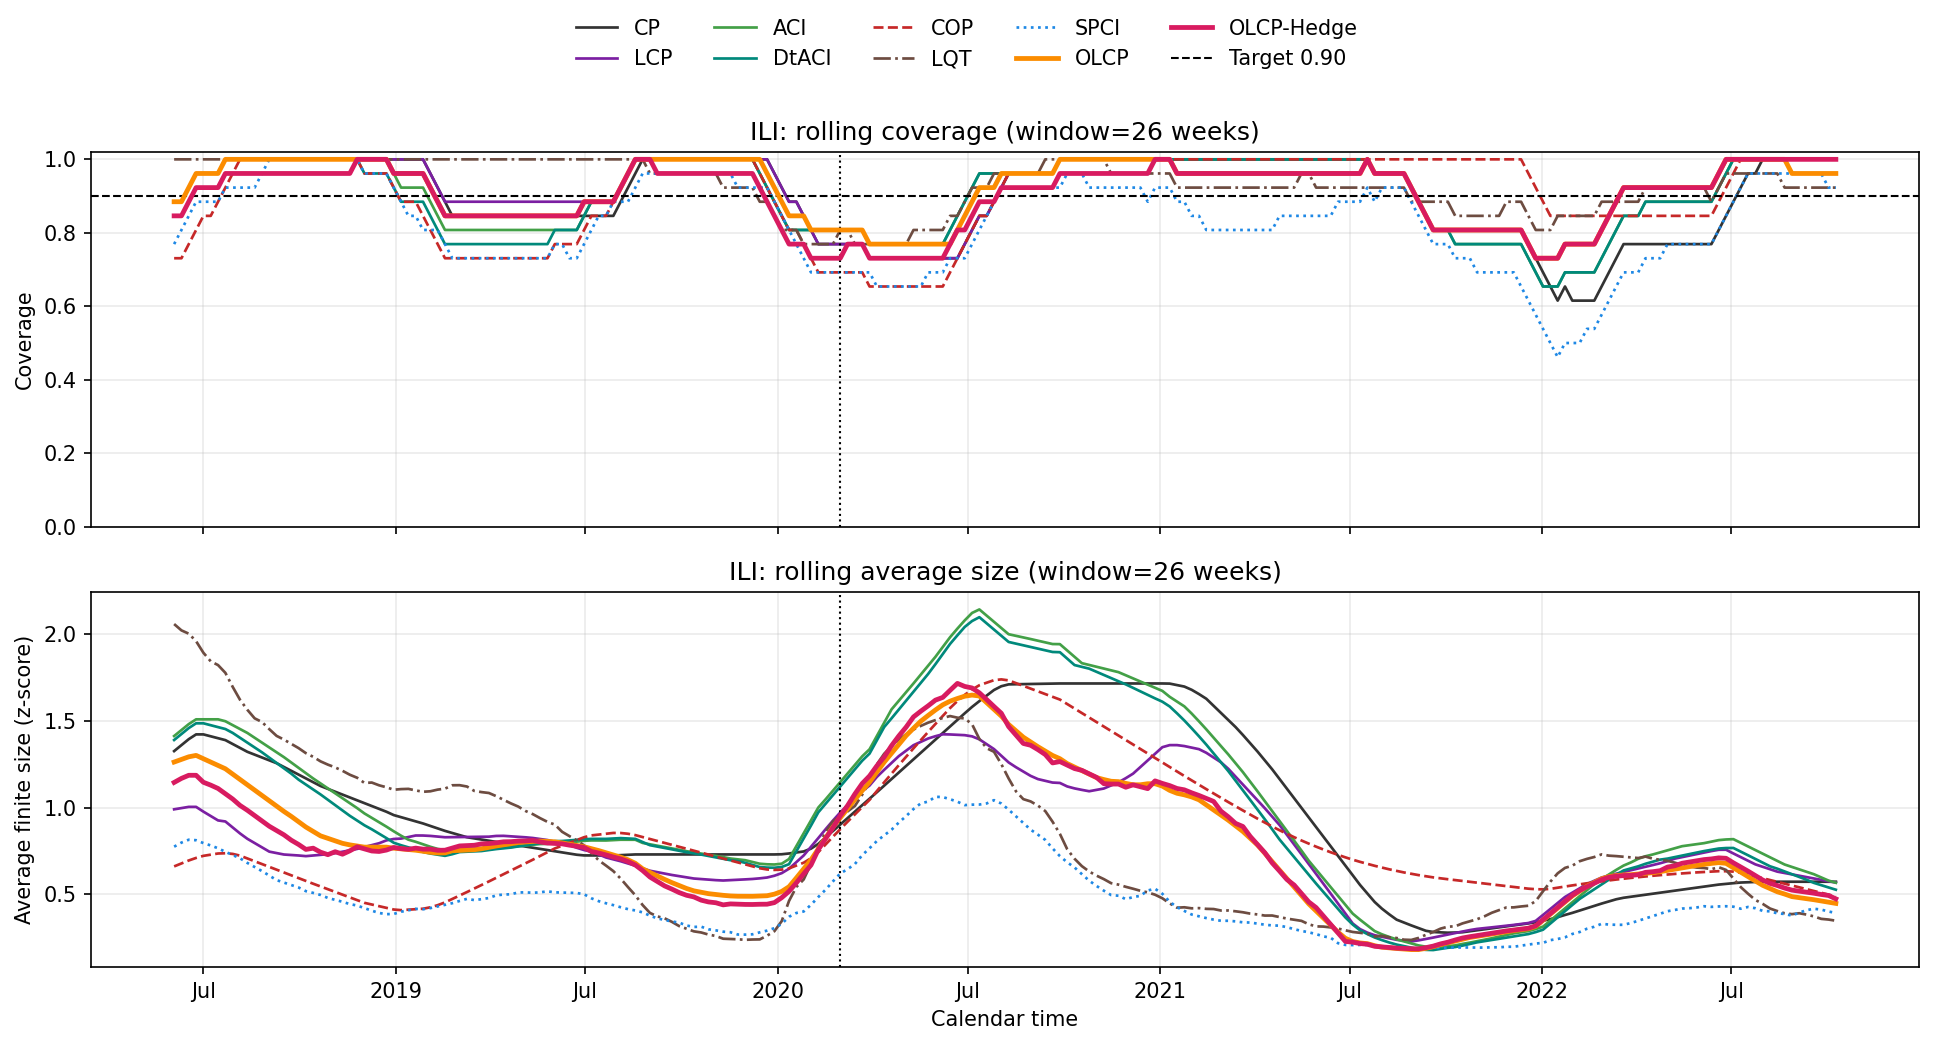

In [7]:
COLORS = dict(zip(METHOD_ORDER, [
    "#333333", "#7B1FA2", "#43A047", "#00897B", "#C62828",
    "#6D4C41", "#1E88E5", "#FB8C00", "#D81B60",
]))
LINESTYLES = {"cop": "--", "lqt": "-.", "spci": ":"}


def plot_rolling_diagnostics(results, window):
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for name in METHOD_ORDER:
        frame = results[name]
        covered = frame["covered"].astype(float)
        finite_size = frame["width"].replace([np.inf, -np.inf], np.nan)
        rolling_coverage = covered.rolling(window, min_periods=window).mean()
        rolling_size = finite_size.rolling(window, min_periods=1).mean()
        start = window - 1
        for ax, values in zip(axes, (rolling_coverage, rolling_size)):
            ax.plot(
                pd.DatetimeIndex(cp_data[0]["ts"])[frame["t"].iloc[start:].to_numpy(dtype=int)], values.iloc[start:],
                label=LABELS[name], color=COLORS[name],
                linestyle=LINESTYLES.get(name, "-"),
                linewidth=2.3 if name in ("olcp", "olcph") else 1.3,
                zorder=4 if name in ("olcp", "olcph") else 2,
            )
    axes[0].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1,
                    label=f"Target {1 - ALPHA:.2f}")
    axes[0].set_title(f"ILI: rolling coverage (window={window} weeks)")
    axes[0].set_ylabel("Coverage")
    axes[0].set_ylim(0, 1.02)
    axes[1].set_title(f"ILI: rolling average size (window={window} weeks)")
    axes[1].set_ylabel("Average finite size (z-score)")
    axes[1].set_xlabel("Calendar time")
    if REFERENCE_DATE is not None:
        for ax in axes:
            ax.axvline(pd.Timestamp(REFERENCE_DATE), color="black", linestyle=":", linewidth=1)
    locator = mdates.MonthLocator(bymonth=(1, 7))
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    for ax in axes:
        ax.grid(alpha=0.25)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    return fig


fig = plot_rolling_diagnostics(results, ROLLING_WINDOW)
# Embed a portable static preview for GitHub without writing additional files.
image_buffer = io.BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=image_buffer.getvalue()))
plt.close(fig)
